There is the full dataset
There is the male only dataset and the female only
There is the Weighed Dataset 

From here I do have to do the K search, for k optimization

In [1]:
import pandas as pd
import numpy as np 
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from imblearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score , davies_bouldin_score
from kmodes.kprototypes import KPrototypes

In [2]:
df = pd.read_csv("MentalHealthSurvey.csv")

In [3]:
def run_kprototypes(dataset, categorical_columns, n_clusters=2,
                    random_state=42, gamma=None):
    """Return the fitted model and cluster labels."""

    categorical_indices = [
        dataset.columns.get_loc(col)
        for col in categorical_columns
    ]

    model = KPrototypes(
        n_clusters=n_clusters,
        init="Huang",
        n_init=10,
        random_state=random_state,
        gamma=gamma,
    )

    labels = model.fit_predict(
        dataset.to_numpy(dtype=object),
        categorical=categorical_indices,
    )

    return model, labels


def dunn_index(distances, labels):
    """Calculate Dunn index from a pairwise distance matrix."""

    distances = np.asarray(distances, dtype=float)
    labels = np.asarray(labels)

    if not 2 <= len(np.unique(labels)) < len(labels):
        raise ValueError("Scoring requires 2 to n_samples - 1 clusters.")

    same_cluster = labels[:, None] == labels[None, :]

    smallest_between = distances[~same_cluster].min()
    largest_within = distances[same_cluster].max()

    if largest_within == 0:
        return np.nan  

    return smallest_between / largest_within


def clustering_table(dataset, labels, model, categorical_columns,
                     name="K-prototypes"):
    """Calculate metrics and adding to DataFrame."""

    if not 2 <= len(pd.unique(labels)) < len(dataset):
        raise ValueError("Scoring requires 2 to n_samples - 1 clusters.")

    distances = np.zeros((len(dataset), len(dataset)))

    for col in dataset.columns:
        if col in categorical_columns:
            values = dataset[col].to_numpy()
            distances += model.gamma * (
                values[:, None] != values[None, :]
            )
        else:
            values = dataset[col].to_numpy(dtype=float)
            distances += (
                values[:, None] - values[None, :]
            ) ** 2

    return pd.DataFrame([{
        "Model": name,
        "Clusters": len(pd.unique(labels)),
        "Gamma": model.gamma,
        "Silhouette Score": silhouette_score(
            distances, labels, metric="precomputed"
        ),
        "Dunn Index": dunn_index(distances, labels)
    }])

In [4]:
runs = {}
Scores = pd.DataFrame()
Male_scores = pd.DataFrame()
Female_scores = pd.DataFrame()

# Full Dataset no weighing (Pure Baseline)

In [5]:
object_columns=['gender', 'university', 'degree_level', 'degree_major',
       'academic_year', 'residential_status', 'campus_discrimination',
       'sports_engagement', 'study_satisfaction',
       'academic_workload ', 'academic_pressure', 'financial_concerns',
       'social_relationships', 'depression', 'anxiety', 'isolation',
       'future_insecurity', 'stress_relief_activities', 'cgpa', 'average_sleep']

#baseline_df = df.drop(columns = object_columns)

In [6]:
model_b, labels_b = run_kprototypes(df, object_columns, gamma=1)

Scores = pd.concat (
    [ Scores, clustering_table(
    df,
    labels_b,
    model_b,
    object_columns,
    name = "Baseline"
),
    ], ignore_index=True
             )

display(Scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.230577,0.090909


# Male Only Full Data

In [7]:
male_df = df.loc[df["gender"]!="Female"].copy()

In [8]:
model_mb, labels_mb = run_kprototypes(male_df, object_columns, gamma=1)

Male_scores = pd.concat (
    [
        Male_scores, clustering_table(
    male_df,
    labels_mb,
    model_mb,
    object_columns,
    name = "Baseline"
), 
    ], ignore_index=True
)

display(Male_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.329219,0.170732


# Female Only Full Data

In [9]:
female_df = df.loc[df["gender"]!="Male"].copy()

In [10]:
model_fb, labels_fb = run_kprototypes(female_df, object_columns, gamma=1)

Female_scores = pd.concat (
    [
        Female_scores, clustering_table(
            female_df, labels_fb, 
            model_fb, object_columns, 
            name = "Baseline"
        )
    ], ignore_index=True
)

display(Female_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.242811,0.416667


# Full Encoded & Scaled Dataset

In [11]:
encoded_df = pd.read_csv("mental_health_preprocessed.csv")

In [12]:
encoded_df.columns

Index(['academic_year', 'cgpa', 'residential_status', 'campus_discrimination',
       'sports_engagement', 'average_sleep', 'degree_major_Computer Science',
       'degree_major_Data Science', 'degree_major_Information Technology',
       'degree_major_Software Engineering', 'gender_Female', 'gender_Male',
       'activity_Creative Outlets', 'activity_Online Entertainment',
       'activity_Outdoor Activities', 'activity_Religious Activities',
       'activity_Sleep', 'activity_Social Connections',
       'activity_Sports and Fitness', 'study_satisfaction',
       'academic_workload ', 'academic_pressure', 'financial_concerns',
       'social_relationships', 'depression', 'anxiety', 'isolation',
       'future_insecurity'],
      dtype='object')

In [13]:
cat_columns = ['academic_year','residential_status', 'campus_discrimination',
       'sports_engagement', 'average_sleep', 'degree_major_Computer Science',
       'degree_major_Data Science', 'degree_major_Information Technology',
       'degree_major_Software Engineering', 'gender_Female', 'gender_Male',
       'activity_Creative Outlets', 'activity_Online Entertainment',
       'activity_Outdoor Activities', 'activity_Religious Activities',
       'activity_Sleep', 'activity_Social Connections',
       'activity_Sports and Fitness', 'study_satisfaction',
       'academic_workload ', 'academic_pressure', 'financial_concerns',
       'social_relationships', 'depression', 'anxiety', 'isolation',
       'future_insecurity']

In [14]:
model_E, labels_E = run_kprototypes(encoded_df, cat_columns, gamma=1)

Scores = pd.concat (
    [
        Scores, clustering_table(
            encoded_df, labels_E, 
            model_E, object_columns, 
            name = "Encoded"
        )
    ], ignore_index=True
)

display(Scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.230577,0.090909
1,Encoded,2,1,0.090385,0.291667


# Male ONLY Encoded & Scaled

In [15]:
male_df_encoded = encoded_df.loc[encoded_df["gender_Male"]==True].copy()

model_ME, labels_ME = run_kprototypes(male_df_encoded, cat_columns, gamma=1)

Male_scores = pd.concat (
    [
        Male_scores, clustering_table(
    male_df_encoded,
    labels_ME,
    model_ME,
    cat_columns,
    name = "Encoded"
), 
    ], ignore_index=True
)

display(Male_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.329219,0.170732
1,Encoded,2,1,0.261056,0.296296


# Female ONLY Encoded & Scaled

In [16]:
female_df_encoded = encoded_df.loc[encoded_df["gender_Female"]==True].copy()

model_FE, labels_FE = run_kprototypes(female_df_encoded, cat_columns, gamma=1)

Female_scores = pd.concat (
    [
        Female_scores, clustering_table(
    female_df_encoded,
    labels_FE,
    model_FE,
    cat_columns,
    name = "Encoded"
), 
    ], ignore_index=True
)

display(Female_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.242811,0.416667
1,Encoded,2,1,0.207452,0.470588


# Feature Engineered Full

In [17]:
engineered_df = pd.read_csv("df_fe.csv")

categorical_variables = [ 'degree_major_Computer Science',
       'degree_major_Data Science', 'degree_major_Information Technology',
       'degree_major_Software Engineering', 'gender_Female', 'gender_Male',
       'activity_Creative Outlets', 'activity_Online Entertainment',
       'activity_Outdoor Activities', 'activity_Religious Activities',
       'activity_Sleep', 'activity_Social Connections',
       'activity_Sports and Fitness', 'study_satisfaction',
       'financial_concerns', 'future_insecurity']

In [18]:
model_engineered, labels_engineered = run_kprototypes(engineered_df, categorical_variables, gamma=1)

Scores = pd.concat(
    [
        Scores, clustering_table(
            engineered_df, labels_engineered, model_engineered,
            categorical_variables, name = "Feature Eng"
        )
    ], ignore_index=True
)

display(Scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.230577,0.090909
1,Encoded,2,1,0.090385,0.291667
2,Feature Eng,2,1,0.421824,0.163821


# Feature Engineered MALE

In [19]:
male_df_engineered = engineered_df.loc[engineered_df["gender_Male"]==True].copy()

model_engineered_male, labels_engineered_male = run_kprototypes(male_df_engineered,
                                                                categorical_variables, 
                                                                gamma=1)

Male_scores = pd.concat(
    [
        Male_scores, clustering_table(
            male_df_engineered, labels_engineered_male,model_engineered_male,
            categorical_variables, name = "Feature Eng"
        )
    ], ignore_index=True
)

display(Male_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.329219,0.170732
1,Encoded,2,1,0.261056,0.296296
2,Feature Eng,2,1,0.395061,0.161925


# Feature Engineered FEMALE

In [20]:
female_df_engineered = engineered_df.loc[engineered_df["gender_Female"]==True].copy()

model_engineered_female, labels_engineered_female = run_kprototypes(female_df_engineered,
                                                                categorical_variables, 
                                                                gamma=1)

Female_scores = pd.concat(
    [
        Female_scores, clustering_table(
            female_df_engineered, labels_engineered_female,model_engineered_female,
            categorical_variables, name = "Feature Eng"
        )
    ], ignore_index=True
)

display(Female_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.242811,0.416667
1,Encoded,2,1,0.207452,0.470588
2,Feature Eng,2,1,0.578634,0.261395


# Scores 

In [21]:
display(Scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.230577,0.090909
1,Encoded,2,1,0.090385,0.291667
2,Feature Eng,2,1,0.421824,0.163821


In [22]:
display(Male_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.329219,0.170732
1,Encoded,2,1,0.261056,0.296296
2,Feature Eng,2,1,0.395061,0.161925


In [23]:
display(Female_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1,0.242811,0.416667
1,Encoded,2,1,0.207452,0.470588
2,Feature Eng,2,1,0.578634,0.261395


# Model Tuning 

## Grid Search

In [24]:
from sklearn.model_selection import ParameterGrid

evaluation_gamma = 1
distances = np.zeros((len(engineered_df), len(engineered_df)))

param_grid = {
    "n_clusters": [2, 3, 4, 5, 6],
    "gamma": [0.10, 0.20, 0.25, 0.5, 1]
}

results = []

for params in ParameterGrid(param_grid):
    model, labels = run_kprototypes(
        engineered_df,
        categorical_variables,
        **params
    )

    if not 2 <= len(np.unique(labels)) < len(labels):
        continue

    results.append({
        "Clusters": params["n_clusters"],
        "Gamma": params["gamma"],
        "Silhouette": silhouette_score(
            distances, labels, metric="precomputed"
        ),
        "Dunn": dunn_index(distances, labels)
    })

grid_scores = pd.DataFrame(results)
grid_scores = grid_scores.sort_values("Silhouette", ascending=False)

display(grid_scores)

,Clusters,Gamma,Silhouette,Dunn
0,2,0.10,0.0,NaN
13,5,0.25,0.0,NaN
23,5,1.00,0.0,NaN
22,4,1.00,0.0,NaN
21,3,1.00,0.0,NaN
20,2,1.00,0.0,NaN
19,6,0.50,0.0,NaN
18,5,0.50,0.0,NaN
17,4,0.50,0.0,NaN
16,3,0.50,0.0,NaN


# Final Evaluation

In [25]:
final_scores = pd.DataFrame()

In [26]:
model_final_b, labels_final_b = run_kprototypes(df, object_columns,n_clusters=2, gamma=0.10)

Scores = pd.concat(
    [Scores, clustering_table(
    df,
    labels_final_b,
    model_final_b,
    object_columns,
    name = "Baseline"
),
    ], ignore_index=True
             )

display(Scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.230577,0.090909
1,Encoded,2,1.0,0.090385,0.291667
2,Feature Eng,2,1.0,0.421824,0.163821
3,Baseline,2,0.1,0.654799,0.060150


In [27]:
#male final baseline

model_mb, labels_mb = run_kprototypes(male_df, object_columns, n_clusters=2, gamma=0.10)

Male_scores = pd.concat (
    [
        Male_scores, clustering_table(
    male_df,
    labels_mb,
    model_mb,
    object_columns,
    name = "Final Baseline"
), 
    ], ignore_index=True
)

display(Male_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.329219,0.170732
1,Encoded,2,1.0,0.261056,0.296296
2,Feature Eng,2,1.0,0.395061,0.161925
3,Final Baseline,2,0.1,0.628859,0.060150


In [28]:
# female final baseline

model_fb, labels_fb = run_kprototypes(female_df, object_columns,n_clusters=2, gamma=0.10)

Female_scores = pd.concat (
    [
        Female_scores, clustering_table(
            female_df, labels_fb, 
            model_fb, object_columns, 
            name = "Final Baseline"
        )
    ], ignore_index=True
)

display(Female_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.242811,0.416667
1,Encoded,2,1.0,0.207452,0.470588
2,Feature Eng,2,1.0,0.578634,0.261395
3,Final Baseline,2,0.1,0.538808,0.250000


In [29]:
# final encoded 

model_final_E, labels_final_E = run_kprototypes(encoded_df, cat_columns,n_clusters=2, gamma=0.10)

Scores = pd.concat(
    [
       Scores, clustering_table(
            encoded_df, labels_final_E, 
            model_final_E, cat_columns, 
            name = "Final Encoded"
        )
    ], ignore_index=True
)

display(Scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.230577,0.090909
1,Encoded,2,1.0,0.090385,0.291667
2,Feature Eng,2,1.0,0.421824,0.163821
3,Baseline,2,0.1,0.654799,0.060150
4,Final Encoded,2,0.1,0.575431,0.153153


In [30]:
#male final encoded
model_ME, labels_ME = run_kprototypes(male_df_encoded, cat_columns,n_clusters=2, gamma=0.10)

Male_scores = pd.concat (
    [
        Male_scores, clustering_table(
    male_df_encoded,
    labels_ME,
    model_ME,
    cat_columns,
    name = "Final Encoded"
), 
    ], ignore_index=True
)

display(Male_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.329219,0.170732
1,Encoded,2,1.0,0.261056,0.296296
2,Feature Eng,2,1.0,0.395061,0.161925
3,Final Baseline,2,0.1,0.628859,0.060150
4,Final Encoded,2,0.1,0.712791,0.316667


In [31]:
#female final encoded
model_FE, labels_FE = run_kprototypes(female_df_encoded, cat_columns,n_clusters=2, gamma=0.10)

Female_scores = pd.concat (
    [
        Female_scores, clustering_table(
    female_df_encoded,
    labels_FE,
    model_FE,
    cat_columns,
    name = "Final Encoded"
), 
    ], ignore_index=True
)

display(Female_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.242811,0.416667
1,Encoded,2,1.0,0.207452,0.470588
2,Feature Eng,2,1.0,0.578634,0.261395
3,Final Baseline,2,0.1,0.538808,0.250000
4,Final Encoded,2,0.1,0.452450,0.571429


In [32]:
#final engineered

model_final_engineered, labels_final_engineered = run_kprototypes(engineered_df, categorical_variables,n_clusters=2,
                                                      gamma=0.10)

Scores = pd.concat(
    [
        Scores, clustering_table(
            engineered_df, labels_final_engineered, model_final_engineered,
            categorical_variables, name = "Final Feature Eng"
        )
    ], ignore_index=True
)

display(Scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.230577,0.090909
1,Encoded,2,1.0,0.090385,0.291667
2,Feature Eng,2,1.0,0.421824,0.163821
3,Baseline,2,0.1,0.654799,0.060150
4,Final Encoded,2,0.1,0.575431,0.153153
5,Final Feature Eng,2,0.1,0.540758,0.071555


In [33]:
# male final engineered
model_engineered_male, labels_engineered_male = run_kprototypes(male_df_engineered,
                                                                categorical_variables,
                                                                n_clusters=2,
                                                                gamma=0.10)

Male_scores = pd.concat(
    [
        Male_scores, clustering_table(
            male_df_engineered, labels_engineered_male,model_engineered_male,
            categorical_variables, name = "Final Feature Eng"
        )
    ], ignore_index=True
)

display(Male_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.329219,0.170732
1,Encoded,2,1.0,0.261056,0.296296
2,Feature Eng,2,1.0,0.395061,0.161925
3,Final Baseline,2,0.1,0.628859,0.060150
4,Final Encoded,2,0.1,0.712791,0.316667
5,Final Feature Eng,2,0.1,0.503328,0.069847


In [34]:
# female final engineered
female_df_engineered = engineered_df.loc[engineered_df["gender_Female"]==True].copy()

model_engineered_female, labels_engineered_female = run_kprototypes(female_df_engineered,
                                                                categorical_variables,
                                                                n_clusters=2,
                                                                gamma=0.10)

Female_scores = pd.concat(
    [
        Female_scores, clustering_table(
            female_df_engineered, labels_engineered_female,model_engineered_female,
            categorical_variables, name = "Final Feature Eng"
        )
    ], ignore_index=True
)

display(Female_scores)

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.242811,0.416667
1,Encoded,2,1.0,0.207452,0.470588
2,Feature Eng,2,1.0,0.578634,0.261395
3,Final Baseline,2,0.1,0.538808,0.250000
4,Final Encoded,2,0.1,0.452450,0.571429
5,Final Feature Eng,2,0.1,0.688086,0.201891


# Final Scores

In [35]:
Scores

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.230577,0.090909
1,Encoded,2,1.0,0.090385,0.291667
2,Feature Eng,2,1.0,0.421824,0.163821
3,Baseline,2,0.1,0.654799,0.060150
4,Final Encoded,2,0.1,0.575431,0.153153
5,Final Feature Eng,2,0.1,0.540758,0.071555


In [36]:
final_scores

""


In [37]:
Male_scores

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.329219,0.170732
1,Encoded,2,1.0,0.261056,0.296296
2,Feature Eng,2,1.0,0.395061,0.161925
3,Final Baseline,2,0.1,0.628859,0.060150
4,Final Encoded,2,0.1,0.712791,0.316667
5,Final Feature Eng,2,0.1,0.503328,0.069847


In [38]:
Female_scores

,Model,Clusters,Gamma,Silhouette Score,Dunn Index
0,Baseline,2,1.0,0.242811,0.416667
1,Encoded,2,1.0,0.207452,0.470588
2,Feature Eng,2,1.0,0.578634,0.261395
3,Final Baseline,2,0.1,0.538808,0.250000
4,Final Encoded,2,0.1,0.452450,0.571429
5,Final Feature Eng,2,0.1,0.688086,0.201891


# Visualizing Metric Scores

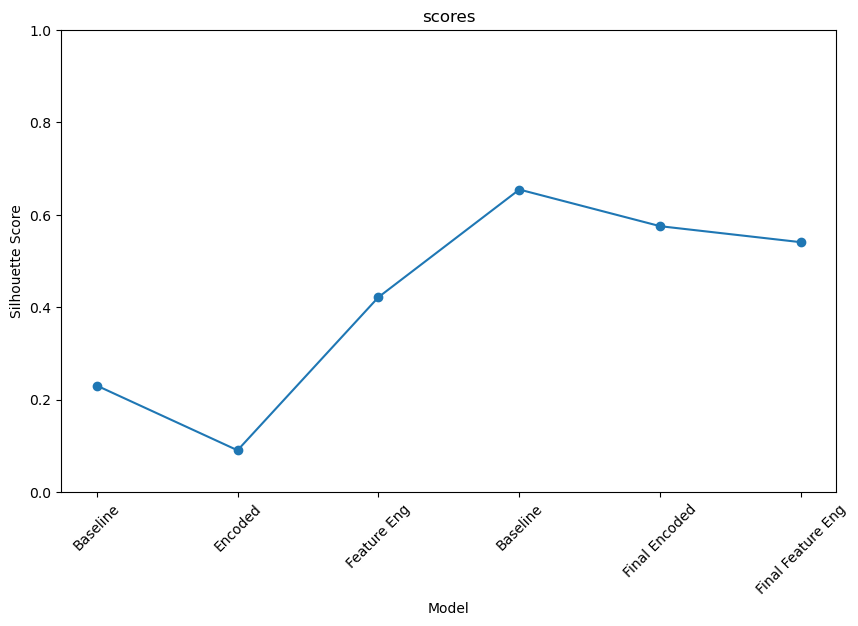

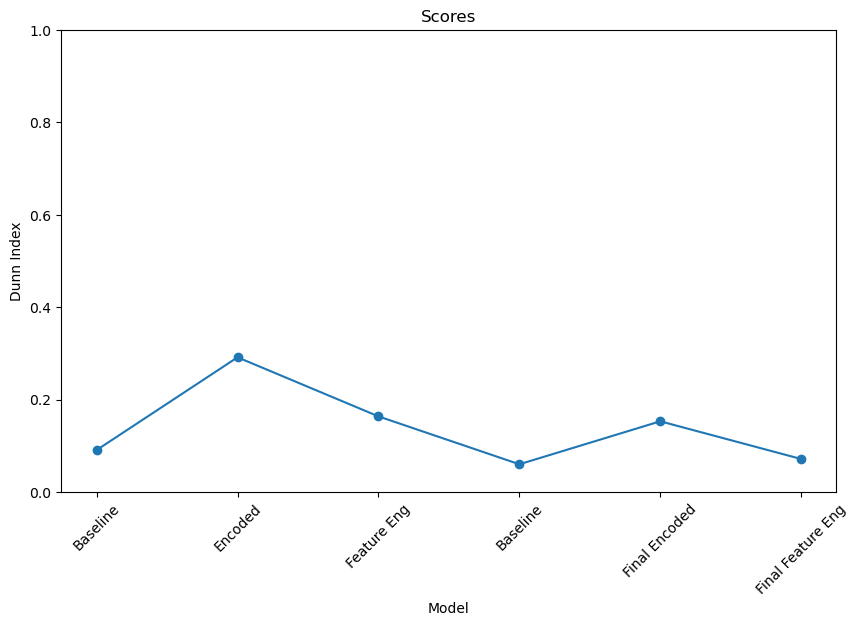

In [39]:
Scores.plot(x="Model", y="Silhouette Score", marker="o",
            title="scores", rot=45, figsize=(10, 6), legend=False)
plt.ylabel("Silhouette Score")
plt.ylim(0, 1)
plt.savefig("scores_silhouette.png", bbox_inches="tight")
plt.show()

Scores.plot(x="Model", y="Dunn Index", marker="o",
            title="Scores", rot=45, figsize=(10, 6), legend=False)
plt.ylabel("Dunn Index")
plt.ylim(0, 1)
plt.savefig("scores_dunn.png", bbox_inches="tight")
plt.show()

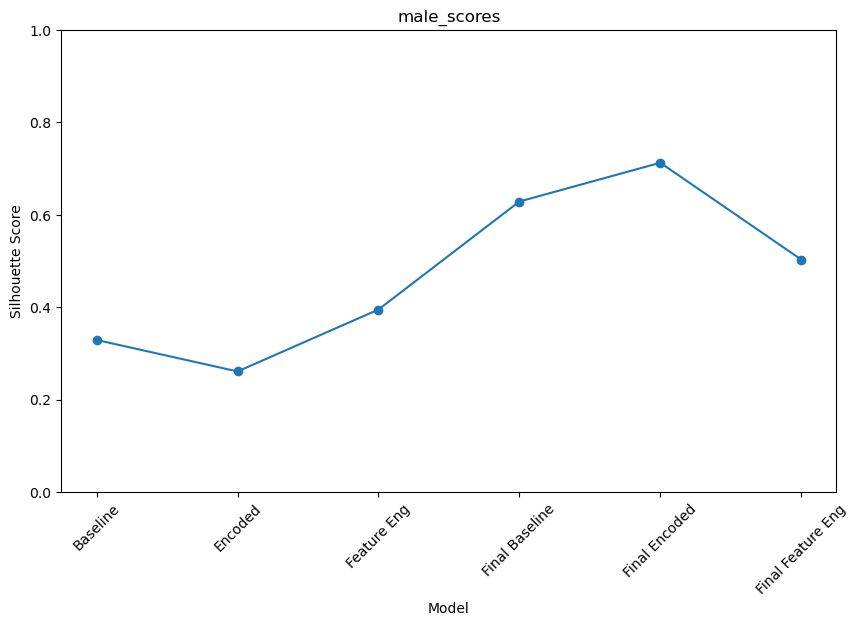

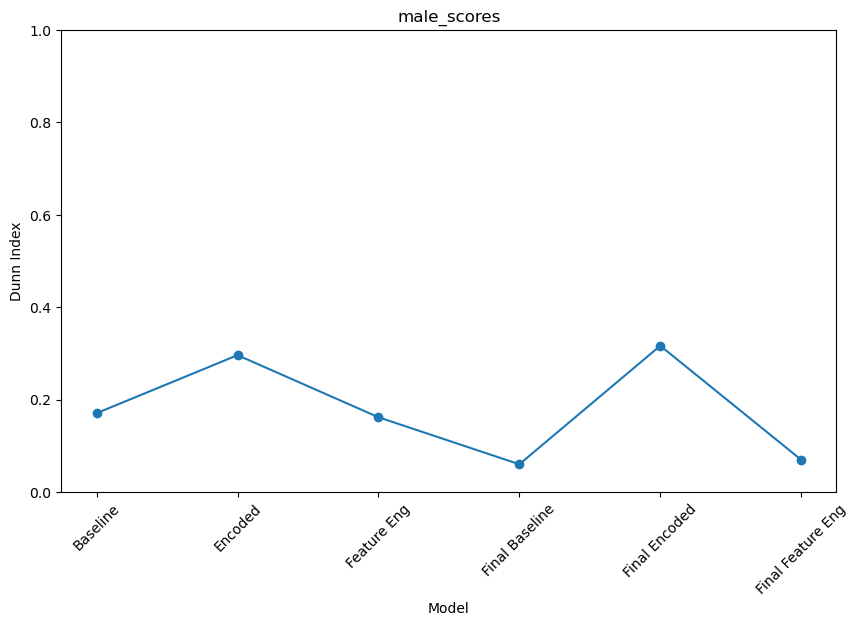

In [40]:
Male_scores.plot(x="Model", y="Silhouette Score", marker="o",
                 title="male_scores", rot=45, figsize=(10, 6), legend=False)
plt.ylabel("Silhouette Score")
plt.ylim(0, 1)
plt.savefig("male_scores_silhouette.png", bbox_inches="tight")
plt.show()

Male_scores.plot(x="Model", y="Dunn Index", marker="o",
                 title="male_scores", rot=45, figsize=(10, 6), legend=False)
plt.ylabel("Dunn Index")
plt.ylim(0, 1)
plt.savefig("male_scores_dunn.png", bbox_inches="tight")
plt.show()

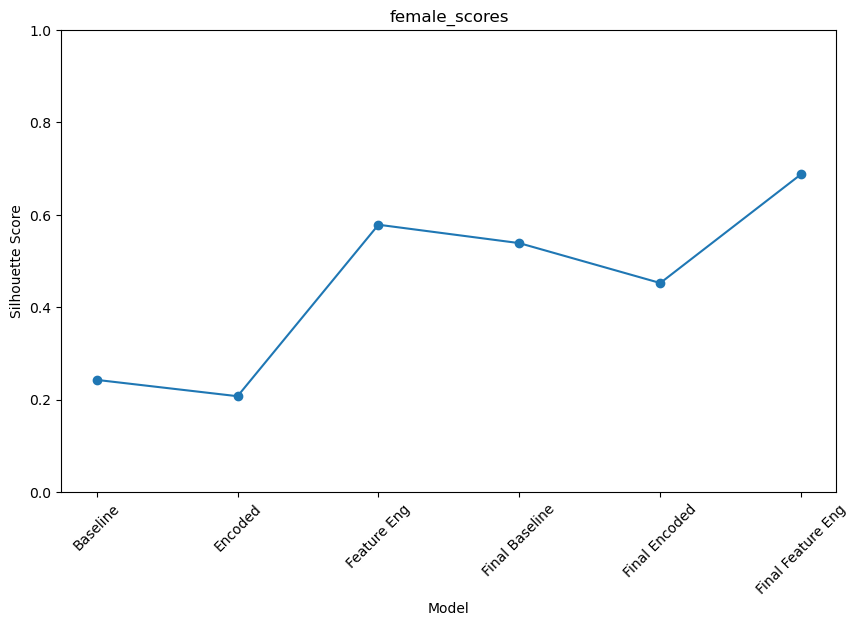

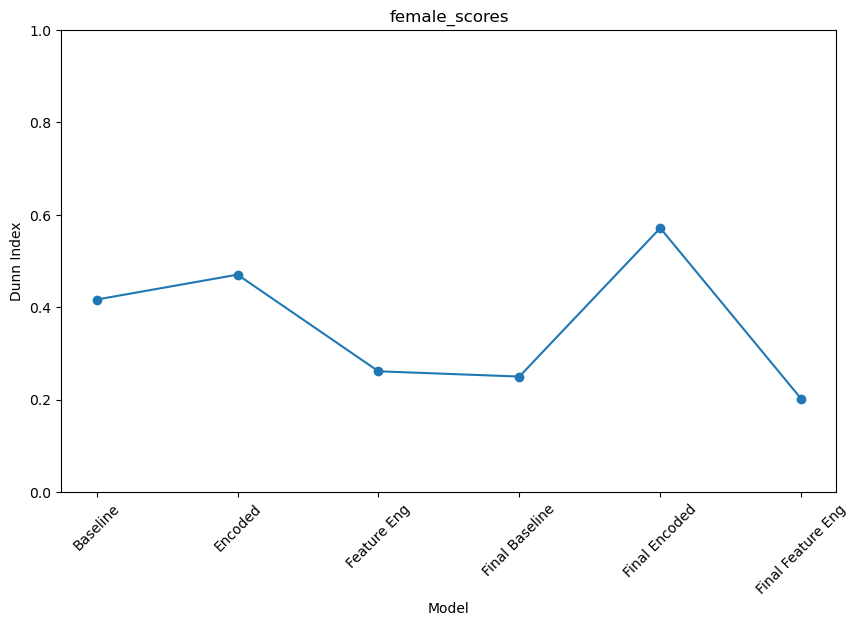

In [41]:
Female_scores.plot(x="Model", y="Silhouette Score", marker="o",
                   title="female_scores", rot=45, figsize=(10, 6), legend=False)
plt.ylabel("Silhouette Score")
plt.ylim(0, 1)
plt.savefig("female_scores_silhouette.png", bbox_inches="tight")
plt.show()

Female_scores.plot(x="Model", y="Dunn Index", marker="o",
                   title="female_scores", rot=45, figsize=(10, 6), legend=False)
plt.ylabel("Dunn Index")
plt.ylim(0, 1)
plt.savefig("female_scores_dunn.png", bbox_inches="tight")
plt.show()

In [42]:
cluster_summary = pd.DataFrame({
    "Characteristic": [
        "Study satisfaction",
        "Academic workload",
        "Academic pressure",
        "Financial concerns",
        "Anxiety",
        "Isolation",
        "Future insecurity",
        "Depression",
        "Social relationships",
        "Sleeping 7–8 hours",
        "Sports/fitness as stress relief",
        "Online entertainment as stress relief"
    ],
    "Cluster 0": [
        4.18, 3.78, 3.63, 3.37, 3.14, 3.16,
        2.92, 3.25, 2.82, 41.18, 19.61, 45.10
    ],
    "Cluster 1": [
        3.44, 4.03, 4.06, 3.34, 3.25, 3.34,
        3.03, 3.03, 2.84, 28.13, 31.25, 34.38
    ]
})

display(cluster_summary)

,Characteristic,Cluster 0,Cluster 1
0,Study satisfaction,4.18,3.44
1,Academic workload,3.78,4.03
2,Academic pressure,3.63,4.06
3,Financial concerns,3.37,3.34
4,Anxiety,3.14,3.25
5,Isolation,3.16,3.34
6,Future insecurity,2.92,3.03
7,Depression,3.25,3.03
8,Social relationships,2.82,2.84
9,Sleeping 7–8 hours,41.18,28.13
